In [1]:

from pathlib import Path
import tensorflow as tf

CLASSES = [
    "Bean",
    "Bitter_Gourd",
    "Bottle_Gourd",
    "Brinjal"
]

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 8
SEED = 42


def load_datasets(data_dir):
    data_dir = Path(data_dir)

    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "train",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=True,
        seed=SEED
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "validation",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "test",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=False
    )

    return train_ds, val_ds, test_ds


In [2]:

import sys
from pathlib import Path
import tensorflow as tf

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "src").exists():
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR))

from src.image_classification.data_loader import (
    load_datasets,
    CLASSES
)

DATA_DIR = PROJECT_DIR / "data" / "Vegetables" / "Vegetable_Images"

train_ds, val_ds, test_ds = load_datasets(DATA_DIR)

print("TensorFlow:", tf.__version__)
print("Classes:", CLASSES)


Found 4000 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
TensorFlow: 2.21.0
Classes: ['Bean', 'Bitter_Gourd', 'Bottle_Gourd', 'Brinjal']


In [3]:

images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Pixel minimum:", float(tf.reduce_min(images)))
print("Pixel maximum:", float(tf.reduce_max(images)))
print("Image dtype:", images.dtype)
print("Unique labels:", sorted(set(labels.numpy().tolist())))


Image shape: (8, 224, 224, 3)
Label shape: (8,)
Pixel minimum: 0.0
Pixel maximum: 255.0
Image dtype: <dtype: 'float32'>
Unique labels: [0, 1, 2]


In [4]:
import importlib
import src.image_classification.data_loader as data_loader

importlib.reload(data_loader)

train_ds, val_ds, test_ds = data_loader.load_datasets(DATA_DIR)

images, labels = next(iter(train_ds))

print("Image shape:", images.shape)
print("Label shape:", labels.shape)
print("Pixel minimum:", float(tf.reduce_min(images)))
print("Pixel maximum:", float(tf.reduce_max(images)))
print("Image dtype:", images.dtype)
print("Class mapping:", dict(enumerate(CLASSES)))

Found 4000 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Found 800 files belonging to 4 classes.
Image shape: (8, 224, 224, 3)
Label shape: (8,)
Pixel minimum: 0.0
Pixel maximum: 255.0
Image dtype: <dtype: 'float32'>
Class mapping: {0: 'Bean', 1: 'Bitter_Gourd', 2: 'Bottle_Gourd', 3: 'Brinjal'}


In [5]:
print(data_loader.__file__)

c:\Users\fondo\deep_learning\dl_tensorflow\AI_Prediction_Platform\src\image_classification\data_loader.py


In [6]:
import inspect

print(inspect.getsource(data_loader.load_datasets))

def load_datasets(data_dir):
    data_dir = Path(data_dir)

    train_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "train",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=True,
        seed=SEED
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "validation",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=False
    )

    test_ds = tf.keras.utils.image_dataset_from_directory(
        data_dir / "test",
        class_names=CLASSES,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=False
    )

    AUTOTUNE = tf.data.AUTOTUNE

    train_ds = train_ds.prefetch(1)
    val_ds = val_ds.prefetch(1)
    test_ds = test_ds.prefetch(1)

    return train_ds, val_ds, test_ds



In [7]:
images = tf.cast(images, tf.float32) / 255.0

In [8]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Rescaling,
    Lambda,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

print("Pretrained model loaded.")
print("Total layers:", len(base_model.layers))
print("Trainable:", base_model.trainable)


Pretrained model loaded.
Total layers: 154
Trainable: False


In [9]:

model = Sequential([
    Input(shape=(224, 224, 3)),

    Lambda(preprocess_input),

    base_model,

    GlobalAveragePooling2D(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(4, activation="softmax")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [10]:

print("Total parameters:", model.count_params())

print(
    "Trainable parameters:",
    sum(
        tf.size(variable).numpy()
        for variable in model.trainable_variables
    )
)

print(
    "Frozen parameters:",
    sum(
        tf.size(variable).numpy()
        for variable in model.non_trainable_variables
    )
)


Total parameters: 2422468
Trainable parameters: 164484
Frozen parameters: 2257986


In [11]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)


In [12]:

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

callbacks = [
    ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_vegetable_mobilenetv2.keras"),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]



In [13]:

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/8


c:\Users\fondo\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


KeyboardInterrupt: 

In [15]:
from tensorflow.keras.models import load_model

MODEL_PATH = (
    PROJECT_DIR / "models" /
    "best_vegetable_mobilenetv2.keras"
)

@tf.keras.utils.register_keras_serializable(package="Custom")
def preprocess_input(x):
    return tf.keras.applications.mobilenet_v2.preprocess_input(x)

best_model = tf.keras.models.load_model(
    MODEL_PATH,
    custom_objects={"preprocess_input": preprocess_input}
)

test_loss, test_accuracy = best_model.evaluate(
    test_ds,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

100/100 ━━━━━━━━━━━━━━━━━━━━ 19s 146ms/step - accuracy: 0.9987 - loss: 0.0056
Test Loss: 0.0056
Test Accuracy: 99.8750%


In [16]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = best_model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    target_names=CLASSES,
    digits=4
))

100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 168ms/step
              precision    recall  f1-score   support

        Bean     0.9950    1.0000    0.9975       200
Bitter_Gourd     1.0000    0.9950    0.9975       200
Bottle_Gourd     1.0000    1.0000    1.0000       200
     Brinjal     1.0000    1.0000    1.0000       200

    accuracy                         0.9988       800
   macro avg     0.9988    0.9988    0.9987       800
weighted avg     0.9988    0.9988    0.9987       800



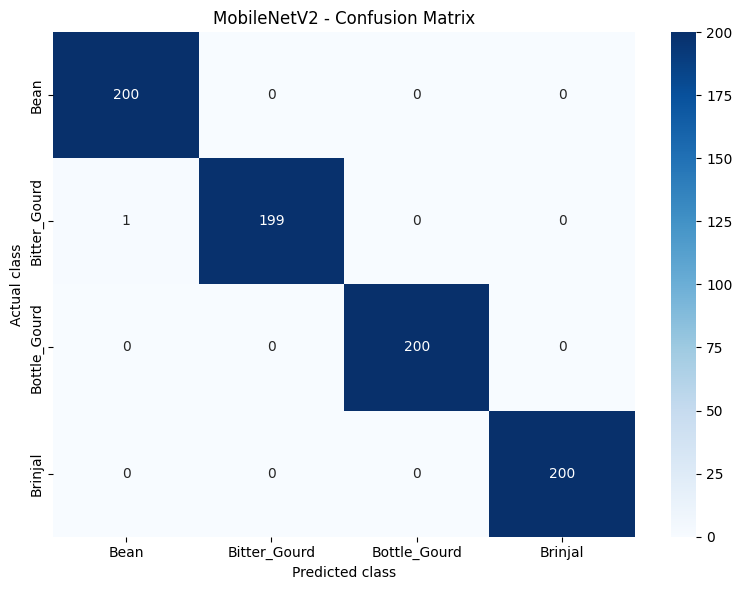

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASSES,
    yticklabels=CLASSES
)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")
plt.title("MobileNetV2 - Confusion Matrix")
plt.tight_layout()
plt.show()